# PBMC single-cell cell-type classifier: does it work on a new donor?

**Author:** Zainab Javed. Code: https://github.com/zainab-123-spec/pbmc-celltype-classifier

Most single-cell tutorials report accuracy *inside one dataset*. Here I train on **PBMC 3k**
(10x Genomics) and also test on **PBMC 68k reduced** (Zheng et al. 2017), a different donor
labelled by a different method. Turn **Internet ON** in Settings (it downloads about 30 MB).

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("scanpy") is None:   # Kaggle images may not ship scanpy
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scanpy"], check=True)

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, scanpy as sc, matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

## Data
Raw counts come from scanpy's copy of the 10x matrix. Labels are the standard tutorial annotation.

In [3]:
raw = sc.datasets.pbmc3k()                 # raw UMI counts, 2,700 cells
proc = sc.datasets.pbmc3k_processed()      # tutorial annotation (louvain names), 2,638 cells
raw.var_names_make_unique()
raw = raw[proc.obs_names].copy()
fine = proc.obs["louvain"].astype(str).to_numpy()
COARSE_3K = {"CD4 T cells": "CD4 T", "CD8 T cells": "CD8 T", "B cells": "B", "NK cells": "NK",
             "CD14+ Monocytes": "Monocyte", "FCGR3A+ Monocytes": "Monocyte",
             "Dendritic cells": "Dendritic", "Megakaryocytes": "Megakaryocyte"}
y3k = np.array([COARSE_3K[v] for v in fine])
print(raw.shape); pd.Series(fine).value_counts()

  0%|          | 0.00/5.58M [00:00<?, ?B/s]

  0%|          | 8.00k/5.58M [00:00<01:58, 49.4kB/s]

  1%|          | 32.0k/5.58M [00:00<00:55, 105kB/s] 

  2%|▏         | 88.0k/5.58M [00:00<00:27, 210kB/s]

  3%|▎         | 200k/5.58M [00:00<00:14, 391kB/s] 

  7%|▋         | 408k/5.58M [00:00<00:07, 699kB/s]

... (6 outputs left out)

 77%|███████▋  | 18.1M/23.5M [00:00<00:00, 95.6MB/s]

100%|██████████| 23.5M/23.5M [00:00<00:00, 95.0MB/s]

(2638, 32738)


CD4 T cells          1144
CD14+ Monocytes       480
B cells               342
CD8 T cells           316
NK cells              154
FCGR3A+ Monocytes     150
Dendritic cells        37
Megakaryocytes         15
Name: count, dtype: int64

In [4]:
def log_normalize(counts, target=1e4):
    x = counts.toarray().astype(np.float32)
    tot = x.sum(1, keepdims=True); tot[tot == 0] = 1
    return np.log1p(x / tot * target)

X = log_normalize(raw.X)
keep = np.asarray((raw.X > 0).sum(0)).ravel() >= 3
X, genes = X[:, keep], np.array(raw.var_names)[keep]
print(X.shape)

(2638, 13656)


In [5]:
class TopVarianceGenes(BaseEstimator, TransformerMixin):
    def __init__(self, n_genes=2000): self.n_genes = n_genes
    def fit(self, x, y=None):
        self.idx_ = np.sort(np.argsort(x.var(0))[::-1][: min(self.n_genes, x.shape[1])]); return self
    def transform(self, x): return x[:, self.idx_]

def make_model(name, seed=0):
    if name == "logreg":
        return make_pipeline(TopVarianceGenes(), StandardScaler(), LogisticRegression(C=0.1, max_iter=3000))
    if name == "knn_pca":
        return make_pipeline(TopVarianceGenes(), StandardScaler(), PCA(50, random_state=seed), KNeighborsClassifier(15))
    return make_pipeline(TopVarianceGenes(), RandomForestClassifier(300, random_state=seed, n_jobs=-1, class_weight="balanced"))

MARKERS = {"CD4 T": ["IL7R", "CD3E", "LDHB"], "CD8 T": ["CD8A", "CD8B", "CD3E"],
           "B": ["MS4A1", "CD79A", "CD79B"], "NK": ["GNLY", "NKG7", "GZMB"],
           "Monocyte": ["LYZ", "CD14", "FCGR3A", "S100A8"], "Dendritic": ["FCER1A", "CST3", "CLEC10A"],
           "Megakaryocyte": ["PPBP", "PF4"]}
def marker_predict(x, gene_names):
    pos = {g: i for i, g in enumerate(gene_names)}
    cls = [c for c in MARKERS if any(g in pos for g in MARKERS[c])]
    z = (x - x.mean(0)) / np.where(x.std(0) == 0, 1, x.std(0))
    s = np.column_stack([z[:, [pos[g] for g in MARKERS[c] if g in pos]].mean(1) for c in cls])
    return np.array(cls)[s.argmax(1)]

## 1. Within-dataset 5-fold CV (coarse labels)

In [6]:
skf = StratifiedKFold(5, shuffle=True, random_state=0)
res = {m: [] for m in ["marker_baseline", "logreg", "knn_pca", "random_forest"]}
for tr, te in skf.split(X, y3k):
    res["marker_baseline"].append(f1_score(y3k[te], marker_predict(X[te], genes), average="macro"))
    for m in ["logreg", "knn_pca", "random_forest"]:
        p = make_model(m).fit(X[tr], y3k[tr]).predict(X[te])
        res[m].append(f1_score(y3k[te], p, average="macro"))
within = {m: (np.mean(v), np.std(v)) for m, v in res.items()}
pd.DataFrame(within, index=["macroF1 mean", "sd"]).T.round(3)

,macroF1 mean,sd
marker_baseline,0.633,0.018
logreg,0.888,0.029
knn_pca,0.872,0.029
random_forest,0.902,0.046


## 2. Train on PBMC 3k, test on PBMC 68k (new donor, FACS-based labels)

In [7]:
b = sc.datasets.pbmc68k_reduced()
x68 = pd.DataFrame(b.raw.X.toarray() if hasattr(b.raw.X, "toarray") else b.raw.X,
                   columns=b.raw.var_names)   # already log-normalised
COARSE_68K = {"CD4+/CD25 T Reg": "CD4 T", "CD4+/CD45RO+ Memory": "CD4 T",
              "CD4+/CD45RA+/CD25- Naive T": "CD4 T", "CD8+ Cytotoxic T": "CD8 T",
              "CD8+/CD45RA+ Naive Cytotoxic": "CD8 T", "CD19+ B": "B", "CD56+ NK": "NK",
              "CD14+ Monocyte": "Monocyte", "Dendritic": "Dendritic"}
lab68 = b.obs["bulk_labels"].astype(str).map(COARSE_68K)
mask = lab68.notna().to_numpy()            # drop 13 CD34+ cells (no 3k equivalent)
shared = [g for g in x68.columns if g in set(genes)]
gi = [int(np.where(genes == g)[0][0]) for g in shared]
Xtr, Xte, yte = X[:, gi], x68[shared].to_numpy()[mask], lab68[mask].to_numpy()
print(len(shared), "shared genes;", len(yte), "test cells")
cross, preds = {}, {}
for m in ["logreg", "knn_pca", "random_forest"]:
    preds[m] = make_model(m).fit(Xtr, y3k).predict(Xte)
    cross[m] = f1_score(yte, preds[m], average="macro")
cross["marker_baseline"] = f1_score(yte, marker_predict(Xte, shared), average="macro")
pd.Series(cross).round(3)

764 shared genes; 687 test cells


logreg             0.786
knn_pca            0.763
random_forest      0.807
marker_baseline    0.704
dtype: float64

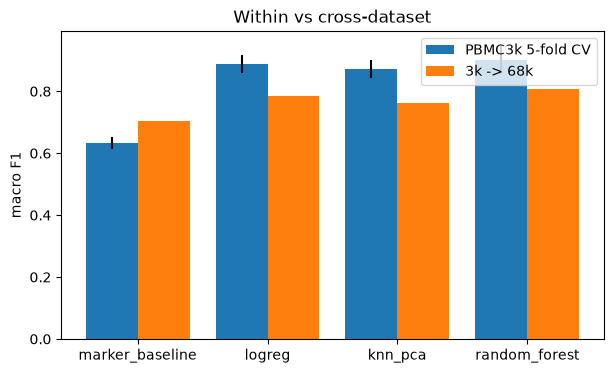

In [8]:
order = ["marker_baseline", "logreg", "knn_pca", "random_forest"]
xs = np.arange(4)
plt.figure(figsize=(7, 4))
plt.bar(xs - 0.2, [within[m][0] for m in order], 0.4, yerr=[within[m][1] for m in order], label="PBMC3k 5-fold CV")
plt.bar(xs + 0.2, [cross[m] for m in order], 0.4, label="3k -> 68k")
plt.xticks(xs, order); plt.ylabel("macro F1"); plt.legend(); plt.title("Within vs cross-dataset"); plt.show()

In [9]:
labs = ["CD4 T", "CD8 T", "B", "NK", "Monocyte", "Dendritic", "Megakaryocyte"]
pd.DataFrame(confusion_matrix(yte, preds["random_forest"], labels=labs), index=labs, columns=labs).iloc[:6]

,CD4 T,CD8 T,B,NK,Monocyte,Dendritic,Megakaryocyte
CD4 T,83,7,4,0,1,0,0
CD8 T,37,50,6,1,3,0,0
B,4,0,91,0,0,0,0
NK,0,6,0,25,0,0,0
Monocyte,0,0,1,0,123,5,0
Dendritic,1,0,0,0,53,186,0


## What I learned

* Within-dataset CV is optimistic: PBMC 3k labels were made by clustering the same data.
* On a new donor, scores drop (see the table above). Most errors are CD8 T predicted as CD4 T,
  and FACS "Dendritic" cells predicted as monocytes. Both pairs are biologically close.
* A marker-gene rule with no training is a strong baseline across datasets.
* Per-dataset z-scoring (tried in the repo) **hurt**, because the two datasets have very
  different cell-type mixes (68k-reduced is 35% dendritic, 3k is 1.4%).